In [33]:
#setup
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from torch.nn.functional import cross_entropy
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()  # 32033
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

block_size = 3


def build_dateset(words):
    X, Y = [], []

    for w in words:
        # fill 3 letters in x fill next in y
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)  # 0.0.0 on first iteration
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

# first we want to shuffle the words
# then we want 80% training set
# then we want 10% dev test
# then we want 10% final test

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

train_data = words[:n1]
dev_data = words[n1:n2]
test_data = words[n2:]

Xtr, Ytr = build_dateset(train_data)
Xdev, Ydev = build_dateset(dev_data)
Xtest, Ytest = build_dateset(test_data)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27
torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [34]:
# MLP revisited
n_embd = 10  # the dimensionality of the character embedding vectors
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),             generator=g)      # torch.Size([27, 10])
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)#*0.2      # torch.Size([30,200])
b1 = torch.randn(n_hidden,                        generator=g)#*0.1      # torch.Size([200])
W2 = torch.randn((n_hidden, vocab_size),          generator=g)*0.1  # torch.Size([200,27])
b2 = torch.randn(vocab_size,                      generator=g)*0    # torch.Size([27,])

parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))  # 11897
for p in parameters:
    p.requires_grad = True

11897


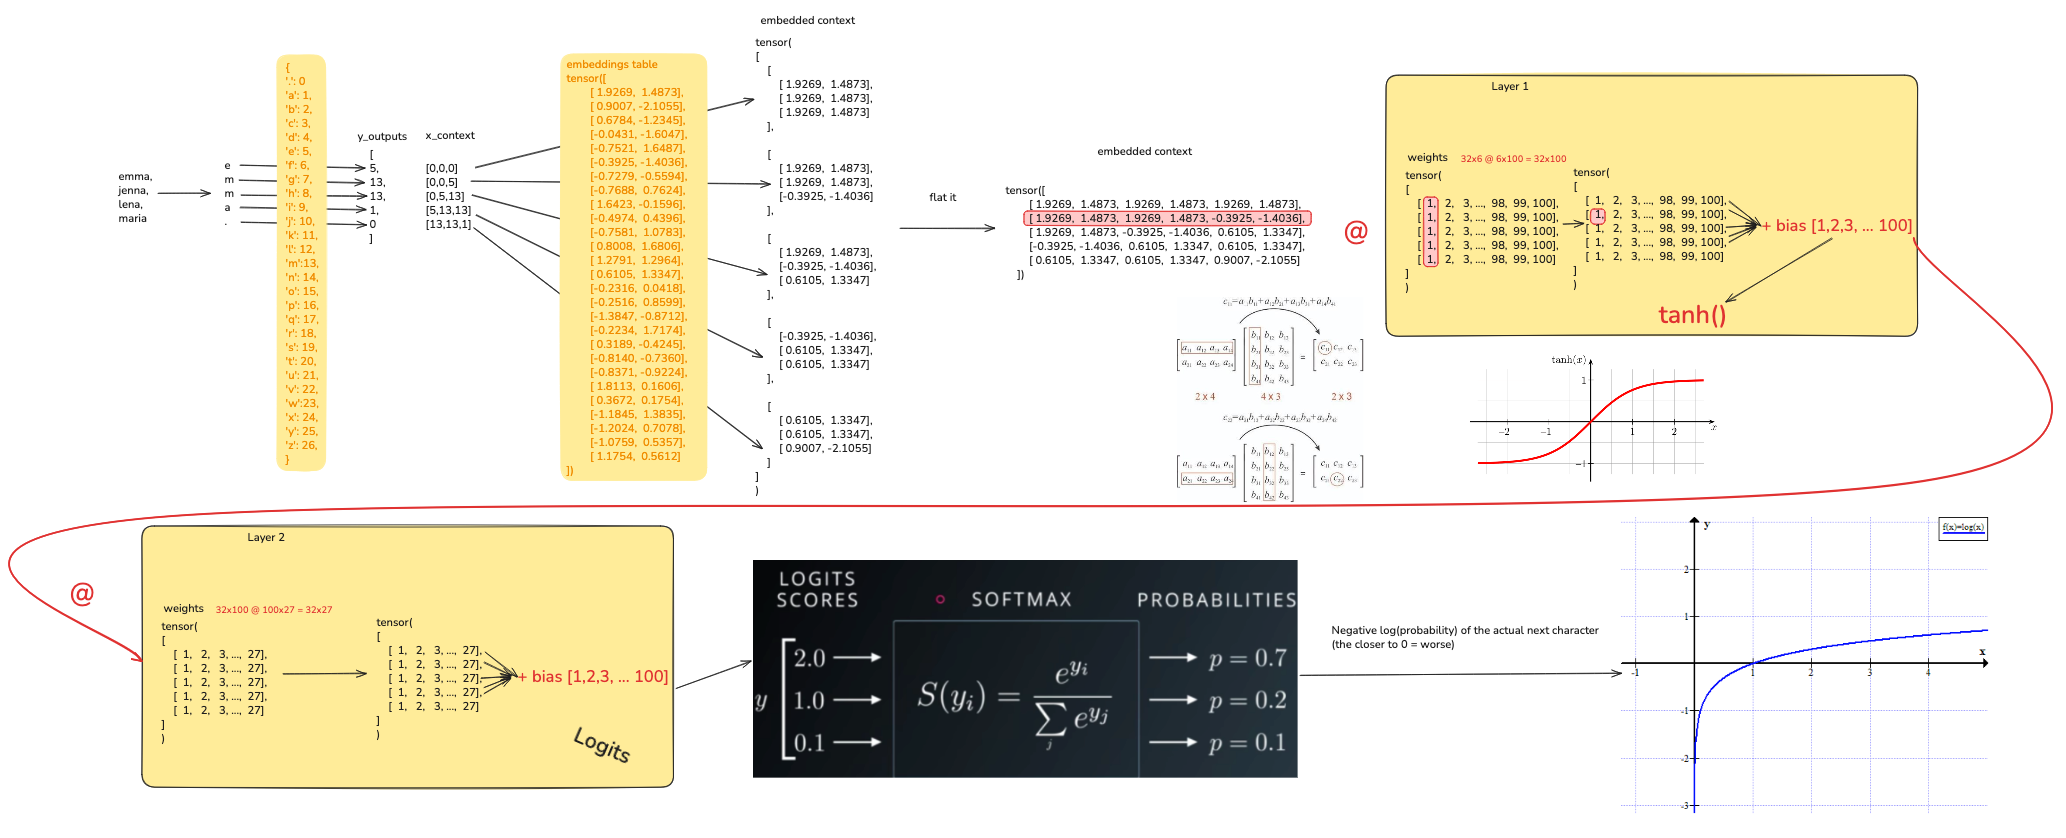

In [35]:
max_steps = 200_000
batch_size = 32
lossi = []

for i in range(200_000):

    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    #forward pass
    emb = C[Xb]  # 32 samples of context of 3 letters each embedded in 10 numbers
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01 if i < 100_000 else 0.001
    for p in parameters:
        p.data += - lr * p.grad

    if i % 10_000 == 0:
        print(f'{i:7d} /{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break

      0 / 200000: 4.2326


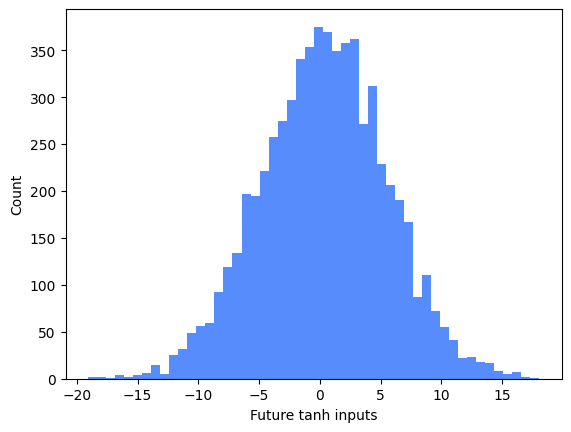

In [36]:
plt.hist(hpreact.view(-1).tolist(), 50);
plt.xlabel("Future tanh inputs"); plt.ylabel("Count");

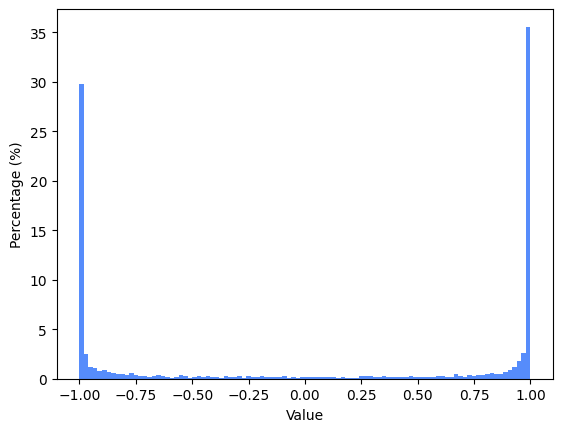

In [37]:
data = h.view(-1).tolist()

plt.hist(data, bins=100, weights=np.ones(len(data)) / len(data) * 100)
plt.ylabel("Percentage (%)"); plt.xlabel("Value"); plt.show()

Due to the way tanh works:
![image.png](attachment:a268ce35-8424-43dc-b1e8-1878f3890dea.png)
If the input is |x|>0.99 it's gradient will be ~0 and it will make every gradient leading to it ~0 too = blocking backpropagation
```
    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad # if t = 1/-1 the grad = 0 so every grad behind that operation = 0

        out._backward = _backward

        return out
```

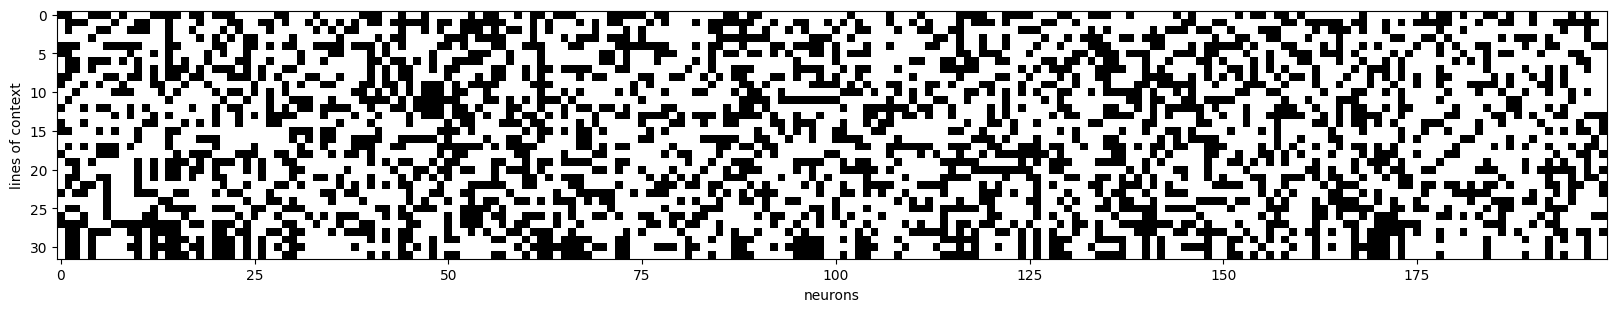

In [38]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')
plt.xlabel("neurons")
plt.ylabel("lines of context")
plt.show();
# so if we had a whole line of white that means that this neuron is DEAD, gradient = 0 for all weights -> no weight is ever changed -> nothing new will be learned ever

In [39]:
# now go back to the w1 and b1 and multiply them by 0.1 -> as you can see now no neurons are potentially dead

In [40]:
# test
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    # x, y = {'train': (Xtr, Ytr),
    #         'val': (Xdev, Ydev),
    #         'test': (Xtest, Ytest),
    #         }[split]

    if split == 'train':
        x, y = Xtr, Ytr
    elif split == 'val':
        x, y = Xdev, Ydev
    elif split == 'test':
        x, y = Xtest, Ytest

    emb = C[x] # (total entries, block_size, n_embd)
    embcat = emb.view(emb.shape[0],-1) # concat into (N, block_size)
    h = torch.tanh(embcat @ W1 + b1) # (N, vocab_size)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 4.046034336090088
val 4.043826103210449


Before
```
train 2.28
val 2.29
```

After fixing the intial loss
```
train 2.16
val 2.19
```

After fixing the activation issue = tanh being to saturated at the intialization
```
train 2.123610258102417
val 2.148090124130249
```

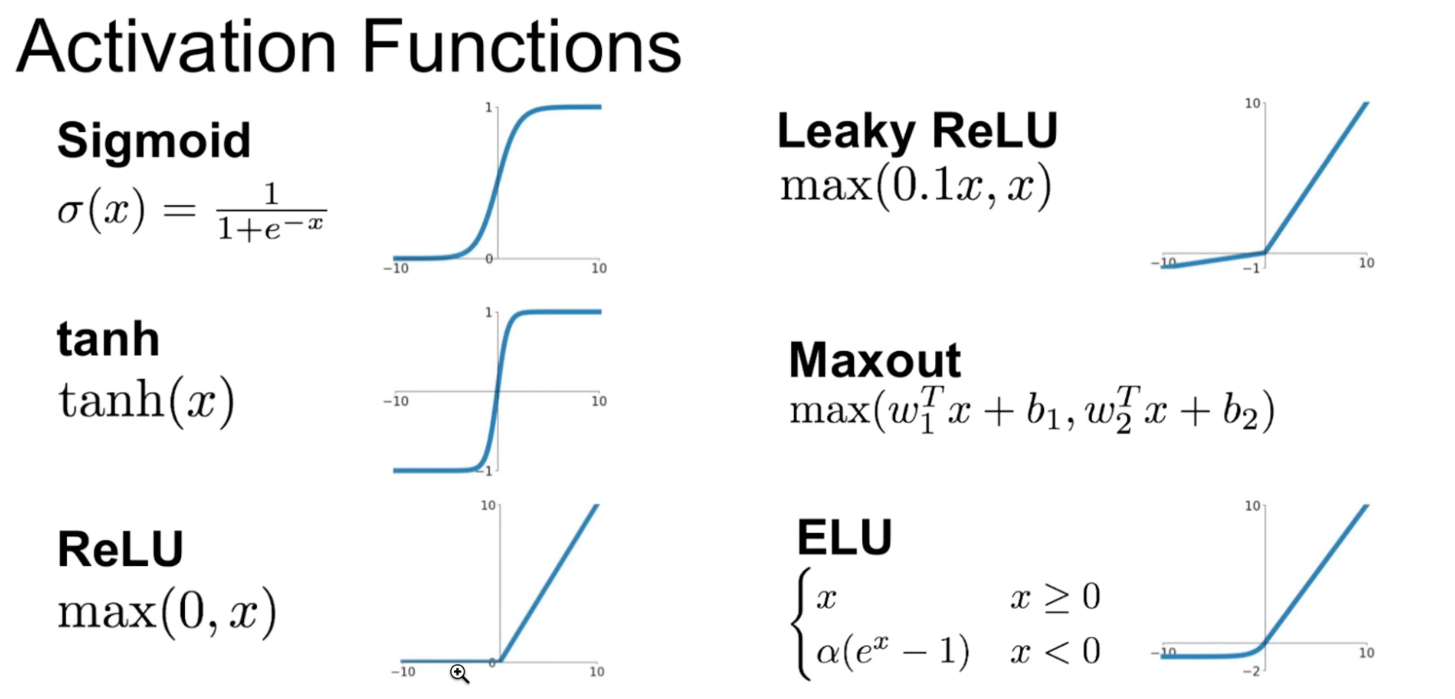